# BÁO CÁO MILESTONE 3: REFERENCE MATCHING PIPELINE
## Chuyên đề: Auto-Labeling & Feature Engineering
**Người thực hiện:** Hoàng (Nhóm 11 - NMKHDL)  
**Mục tiêu:** Xây dựng pipeline gán nhãn tự động (Auto-Labeling) có độ tin cậy cao và bộ kỹ nghệ đặc trưng toàn diện (24 đặc trưng thuộc 6 nhóm) nhằm phục vụ mô hình học máy ghép nối mục trích dẫn BibTeX (Milestone 2) với siêu dữ liệu bài báo tham chiếu arXiv (Milestone 1 - Semantic Scholar API), đánh giá bằng chỉ số **MRR@5**.


## 1. Tổng quan & Khung bài toán (Problem Framing)

### 1.1. Không gian ứng viên (Candidate Space)
Trong mỗi ấn phẩm khoa học (publication) chứa $m$ mục BibTeX trích dẫn và $n$ bài báo tham chiếu cào được từ Semantic Scholar có arXiv ID:
- Không gian ứng viên tạo thành ma trận nhị phân kích thước $m \times n$.
- Mỗi ô $(i, j)$ mang nhãn dương (1 - **Positive / Match**) nếu mục BibTeX $i$ ứng với bài báo tham chiếu $j$, ngược lại mang nhãn âm (0 - **Negative / Non-match**).
- Với mỗi mục BibTeX, chỉ có tối đa một tham chiếu đúng (one-to-one mapping). Nếu mục BibTeX không tương ứng với bài arXiv nào trong $n$ bài tham chiếu thì toàn bộ hàng mang giá trị 0 (all-negative row).

### 1.2. Định dạng bài toán Học Máy (Learning to Rank / Binary Classification)
- **Đầu vào:** Mỗi cặp ứng viên $(BibTeX_i, Reference_j)$ được biểu diễn bằng một vector đặc trưng đa chiều $x_{ij} \in \mathbb{R}^{24}$ thuộc 6 nhóm đặc trưng.
- **Mục tiêu:** Mô hình học máy dự đoán xác suất $P(y_{ij} = 1 \mid x_{ij})$.
- **Đánh giá:** Với mỗi mục BibTeX $i$, sắp xếp các ứng viên $j$ theo xác suất giảm dần để lấy top 5 ứng viên ($cand_1 \dots cand_5$), tính chỉ số **MRR@5**:
$$\text{MRR@5} = \frac{1}{|Q|} \sum_{i=1}^{|Q|} \frac{1}{\text{rank}_i}$$


## 2. Phương pháp Gán nhãn Tự động (Auto-Labeling Pipeline)

Theo đặc tả của Milestone 3:
- Pool gán nhãn tự động chiếm ít nhất **10%** số publication ngoài tập thủ công (và tối thiểu $2k = 8$ publications với nhóm 4 người).
- Thuật toán gán nhãn tự động phải gán nhãn cho **toàn bộ** các mục BibTeX trong publication được chọn.

### 2.1. Các quy tắc Heuristics có độ chuẩn xác cao (`AutoReferenceMatcher`)
Để đảm bảo độ chính xác cực cao (hạn chế tối đa nhiễu nhãn), hệ thống áp dụng 4 tầng quy tắc theo thứ tự ưu tiên giảm dần:
1. **Rule 1 — Direct arXiv ID Match (`direct_arxiv_id`, độ tin cậy `1.0`):** Trích xuất định danh arXiv qua biểu thức chính quy (Regex) từ các trường `eprint`, `url`, `note` của BibTeX và đối khớp trực tiếp với `ref_arxiv_id`.
2. **Rule 2a — Exact Normalized Title + Verification (`exact_title_verified`, độ tin cậy `0.98`):** Chuẩn hóa tiêu đề (loại bỏ cú pháp LaTeX, dấu câu, đưa về chữ thường). Khớp khi $\max(\text{Token Sort Ratio}, \text{Levenshtein Ratio}) \ge 98\%$ kèm ít nhất một điều kiện xác thực: có tác giả trùng, hoặc năm xuất bản lệch $\le 1$ năm, hoặc vượt ứng viên thứ hai $\text{margin} \ge 10$ điểm.
3. **Rule 2b — High Title Similarity + Metadata (`high_title_and_metadata`, độ tin cậy `0.88–0.98`):** Khớp khi độ tương đồng tiêu đề $\ge 88\%$ kèm xác thực mạnh (Jaccard tác giả $\ge 0.20$ hoặc trùng họ tác giả đầu **và** năm lệch $\le 1$ năm) hoặc xác thực vừa (có trùng tác giả **và** $\text{margin} \ge 5.0$ điểm).
4. **Rule 2c — Unambiguous Title Match (`unambiguous_title_match`, độ tin cậy `0.94–0.98`):** Khi thiếu metadata xác thực, chỉ chấp nhận khớp nếu độ tương đồng tiêu đề $\ge 94\%$ **và** vượt ứng viên thứ hai một khoảng cách an toàn $\text{margin} \ge 12.0$ điểm.
5. **Trường hợp không khớp (`none` / All-negative row):** Nếu không có ứng viên nào vượt qua các quy tắc trên, mục BibTeX được gán nhãn `None`.


In [1]:
import json
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

if "display" not in globals():
    try:
        from IPython.display import display
    except ImportError:
        display = print

plt.rcParams.update({
    "axes.grid": True,
    "grid.alpha": 0.3,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 10,
})

# Xác định thư mục gốc dự án (chỉ hiển thị đường dẫn tương đối)
project_root = Path.cwd().parent if Path.cwd().name == "reports" else Path.cwd()
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

manual_dir = project_root / "data" / "manual_labeling"
matching_dir = project_root / "data" / "matching"
sources_manual = project_root / "sourcesManual20"

print(f"Manual labels : {manual_dir.relative_to(project_root)}")
print(f"Data matching : {matching_dir.relative_to(project_root)}")
print(f"Sources manual: {sources_manual.relative_to(project_root)}")


Manual labels : data\manual_labeling
Data matching : data\matching
Sources manual: sourcesManual20


In [2]:
from src.model.data_cleaning import collect_bibtex_tables, flatten_references_json, clean_references_table, read_table
from src.model.auto_labeler import run_auto_labeling_pipeline, validate_auto_labels
from src.model.modeling import normalize_labels
from src.model.run_matching import publication_key

# 1. Tải dữ liệu thực tế từ 20 bài báo manual pool
bibtex_manual = collect_bibtex_tables(sources_manual)
bibtex_manual["arxiv_id"] = bibtex_manual["arxiv_id"].map(publication_key)

raw_refs_manual = flatten_references_json(sources_manual)
refs_manual = clean_references_table(raw_refs_manual)

# 2. Tải nhãn thủ công (Ground Truth) do nhóm thực hiện trên 20 bài báo
manual_labels = normalize_labels(read_table(manual_dir / "manual_labels.csv"), default_source="manual")
manual_labels["arxiv_id"] = manual_labels["arxiv_id"].map(publication_key)
manual_pubs = sorted(manual_labels["arxiv_id"].unique())

print(f"Số ấn phẩm trong tập manual : {len(manual_pubs)}")
print(f"Số mục trích dẫn BibTeX     : {len(manual_labels):,}")

# 3. Chạy pipeline Auto-Labeling trên chính 20 bài manual để kiểm tra độ tin cậy
auto_on_manual = run_auto_labeling_pipeline(bibtex_manual, refs_manual, target_publication_ids=manual_pubs)

# Thống kê số lượng khớp theo từng quy tắc Heuristic
method_counts = (
    auto_on_manual["method"]
    .fillna("none")
    .value_counts()
    .rename_axis("Quy tắc gán nhãn (method)")
    .reset_index(name="Số mục BibTeX")
)
method_counts["Tỷ lệ (%)"] = (method_counts["Số mục BibTeX"] / len(auto_on_manual) * 100).round(2)
print("\n=== PHÂN BỐ QUY TẮC AUTO-LABELER TRÊN 20 BÀI MANUAL ===")
display(method_counts)

# 4. Kiểm định chất lượng của Auto-Labeler so với nhãn tay
validation_results = validate_auto_labels(auto_on_manual, manual_labels)

val_display_df = pd.DataFrame([
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Số mục trích dẫn đối sánh (entries_compared)", "Giá trị": f"{validation_results['entries_compared']:,}"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Số cặp Auto-Labeler tìm thấy (auto_matches)", "Giá trị": f"{validation_results['auto_matches']:,}"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Số cặp Nhãn tay xác nhận (manual_matches)", "Giá trị": f"{validation_results['manual_matches']:,}"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ chính xác (Precision)", "Giá trị": f"{float(validation_results['precision']) * 100:.2f}%"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ bao phủ (Recall)", "Giá trị": f"{float(validation_results['recall']) * 100:.2f}%"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ đồng thuận khi không có match (No-match agreement)", "Giá trị": f"{float(validation_results['no_match_agreement']) * 100:.2f}%"},
    {"Chỉ số kiểm định Auto Labeler (trên 20 bài Manual)": "Độ chính xác tổng thể (Accuracy)", "Giá trị": f"{float(validation_results['accuracy']) * 100:.2f}%"},
])
print("\n=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY CỦA AUTO-LABELER TRÊN POOL 20 BÀI GÁN NHÃN TAY ===")
display(val_display_df)

# Đồng bộ lưu kết quả vào data/matching/auto_label_validation.json
val_file = matching_dir / "auto_label_validation.json"
val_file.write_text(json.dumps(validation_results, indent=2, ensure_ascii=False), encoding="utf-8")
print(f"\n-> Đã lưu kết quả tham khảo vào: {val_file.relative_to(project_root)}")


Số ấn phẩm trong tập manual : 20
Số mục trích dẫn BibTeX     : 881

=== PHÂN BỐ QUY TẮC AUTO-LABELER TRÊN 20 BÀI MANUAL ===

=== KẾT QUẢ KIỂM ĐỊNH ĐỘ TIN CẬY CỦA AUTO-LABELER TRÊN POOL 20 BÀI GÁN NHÃN TAY ===

-> Đã lưu kết quả tham khảo vào: data\matching\auto_label_validation.json


,Quy tắc gán nhãn (method),Số mục BibTeX,Tỷ lệ (%)
0,none,453,51.42
1,exact_title_verified,267,30.31
2,direct_arxiv_id,158,17.93
3,high_title_and_metadata,3,0.34


,Chỉ số kiểm định Auto Labeler (trên 20 bài Manual),Giá trị
0,Số mục trích dẫn đối sánh (entries_compared),881
1,Số cặp Auto-Labeler tìm thấy (auto_matches),428
2,Số cặp Nhãn tay xác nhận (manual_matches),453
3,Độ chính xác (Precision),99.77%
4,Độ bao phủ (Recall),94.26%
5,Độ đồng thuận khi không có match (No-match agr...,99.77%
6,Độ chính xác tổng thể (Accuracy),96.94%


## 3. Kỹ nghệ đặc trưng (Feature Engineering) — 6 Nhóm / 24 Đặc trưng

Để mô hình học máy phân biệt chính xác giữa cặp đúng (Positive) và các cặp nhiễu (Negative), chúng tôi thiết kế **6 nhóm đặc trưng** toàn diện với tổng cộng **24 chiều**:

| STT | Nhóm đặc trưng (Group) | Số lượng | Danh sách Features & Ý nghĩa |
| :--- | :--- | :---: | :--- |
| 1 | **Title Features** | **8** | `sim_title_exact` (trùng tuyệt đối), `sim_title_ratio` (Levenshtein), `sim_title_token_sort` (bỏ qua thứ tự từ), `sim_title_token_set` (xử lý phụ đề/viết hoa), `sim_title_jaccard_words` (Jaccard từ), `sim_title_char_3gram` (3-gram ký tự bắt lỗi chính tả/gõ tắt), `feat_title_length_diff` (chênh lệch số ký tự), `feat_title_word_count_diff` (chênh lệch số từ). |
| 2 | **Author Features** | **5** | `sim_author_exact` (trùng danh sách tác giả chuẩn hóa), `sim_author_jaccard` (Jaccard tác giả), `feat_author_first_match` (trùng họ tác giả đầu tiên - First Author Surname match), `feat_author_count_diff` (chênh lệch số tác giả), `feat_author_missing` (cờ thiếu tác giả). |
| 3 | **Year Features** | **3** | `feat_year_exact` (trùng năm), `feat_year_diff` (chênh lệch tuyệt đối $|Year_{bib} - Year_{ref}|$), `feat_year_missing` (cờ thiếu năm). |
| 4 | **Identifier Features** | **2** | `feat_id_exact_match` (trùng khớp tuyệt đối mã định danh arXiv), `feat_has_bib_arxiv_id` (cờ mục BibTeX có trường arXiv hay không). |
| 5 | **Context & Hierarchy (M2)** | **3** | `feat_citation_depth` (độ sâu section chứa trích dẫn từ Milestone 2), `feat_citation_frequency` (tần suất trích dẫn trong toàn bài), `feat_is_in_intro_or_related` (cờ trích dẫn nằm trong phần mở đầu hoặc công trình liên quan). |
| 6 | **Group-Relative Features** | **3** | `feat_title_sim_rank` (thứ hạng tương đồng tiêu đề của ứng viên này so với các ứng viên khác trong cùng mục BibTeX), `feat_title_sim_diff_to_max` (khoảng cách điểm tới ứng viên cao nhất), `feat_candidate_count` (tổng số ứng viên khả dĩ). |


In [3]:
# Tải ma trận đặc trưng thật (Candidate Matrix) đã được trích xuất
matrix = pd.read_parquet(matching_dir / "candidate_matrix.parquet")
print(f"Kích thước Candidate Matrix thực tế: {matrix.shape[0]:,} hàng x {matrix.shape[1]} cột")

# Thống kê phân bố nhãn (Class Imbalance thực tế của bài toán Ranking)
label_counts = matrix["label"].value_counts().rename({0.0: "Negative (0)", 1.0: "Positive (1)"})
label_ratio = (matrix["label"].value_counts(normalize=True) * 100).rename({0.0: "Negative (0)", 1.0: "Positive (1)"})
label_summary = pd.DataFrame({"Số lượng (cặp)": label_counts, "Tỷ lệ (%)": label_ratio.round(2)})
print("\n=== PHÂN BỐ NHÃN TRONG TOÀN BỘ MA TRẬN ỨNG VIÊN ===")
display(label_summary)

# Định nghĩa danh sách 24 đặc trưng theo 6 nhóm
feature_groups = {
    "1. Title Features (8)": [
        "sim_title_exact", "sim_title_ratio", "sim_title_token_sort", "sim_title_token_set",
        "sim_title_jaccard_words", "sim_title_char_3gram", "feat_title_length_diff", "feat_title_word_count_diff"
    ],
    "2. Author Features (5)": [
        "sim_author_exact", "sim_author_jaccard", "feat_author_first_match",
        "feat_author_count_diff", "feat_author_missing"
    ],
    "3. Year Features (3)": [
        "feat_year_exact", "feat_year_diff", "feat_year_missing"
    ],
    "4. Identifier Features (2)": [
        "feat_id_exact_match", "feat_has_bib_arxiv_id"
    ],
    "5. Context & Hierarchy Features (3)": [
        "feat_citation_depth", "feat_citation_frequency", "feat_is_in_intro_or_related"
    ],
    "6. Group-Relative Features (3)": [
        "feat_title_sim_rank", "feat_title_sim_diff_to_max", "feat_candidate_count"
    ]
}

all_24_features = [f for feats in feature_groups.values() for f in feats]
assert len(all_24_features) == 24, "Phải có đúng 24 features!"
print(f"\nĐã xác nhận đầy đủ {len(all_24_features)} features thuộc 6 nhóm chuẩn xác theo FeatureExtractor.")


Kích thước Candidate Matrix thực tế: 34,377 hàng x 32 cột

=== PHÂN BỐ NHÃN TRONG TOÀN BỘ MA TRẬN ỨNG VIÊN ===

Đã xác nhận đầy đủ 24 features thuộc 6 nhóm chuẩn xác theo FeatureExtractor.


,Số lượng (cặp),Tỷ lệ (%)
label,,
Negative (0),33736,98.14
Positive (1),641,1.86


## 4. Phân tích Tương quan & Mức độ Phân tách Đặc trưng (Feature Separation Analysis)

Một đặc trưng có khả năng phân loại mạnh khi phân phối giá trị của nó giữa hai nhóm:
- Nhóm nhãn dương (**Positive Pairs / label = 1**): Cặp BibTeX và tham chiếu arXiv thực sự trùng nhau.
- Nhóm nhãn âm (**Negative Pairs / label = 0**): Cặp ghép sai hoặc ứng viên nhiễu.

có sự cách biệt rõ ràng. Do 24 đặc trưng có đơn vị khác nhau (tỷ lệ trong đoạn $[0, 1]$ so với độ chênh lệch ký tự, số từ, thứ hạng ứng viên), ngoài hiệu trung bình thô $\Delta = \mu_{\text{pos}} - \mu_{\text{neg}}$, chúng tôi tính thêm **độ phân tách chuẩn hóa Cohen's $d$ (Standardized Mean Difference)**:
$$d = \frac{\mu_{\text{pos}} - \mu_{\text{neg}}}{\sigma_{\text{pooled}}}, \quad \sigma_{\text{pooled}} = \sqrt{\frac{\sigma_{\text{pos}}^2 + \sigma_{\text{neg}}^2}{2}}$$
để so sánh công bằng sức mạnh phân tách giữa tất cả 24 đặc trưng trên cùng một thang đo độ lệch chuẩn.


In [4]:
# Tính trung bình và độ lệch chuẩn theo nhãn Positive (1) vs Negative (0)
pos_df = matrix[matrix["label"] == 1.0][all_24_features]
neg_df = matrix[matrix["label"] == 0.0][all_24_features]

mean_pos = pos_df.mean()
mean_neg = neg_df.mean()
std_pooled = np.sqrt((pos_df.var(ddof=1) + neg_df.var(ddof=1)) / 2.0).replace(0, np.nan)

separation_table = pd.DataFrame({
    "Group": [next(g for g, fs in feature_groups.items() if f in fs) for f in all_24_features],
    "Positive (1)": mean_pos,
    "Negative (0)": mean_neg,
    "Raw Diff": mean_pos - mean_neg,
    "Cohen's d": (mean_pos - mean_neg) / std_pooled,
}, index=all_24_features)
separation_table["|Cohen's d|"] = separation_table["Cohen's d"].abs()

separation_display = separation_table.sort_values(by="|Cohen's d|", ascending=False)
print("=== BẢNG PHÂN TÍCH ĐỘ PHÂN TÁCH 24 FEATURES GIỮA POSITIVE VÀ NEGATIVE (SẮP XẾP THEO |COHEN'S d|) ===")
display(separation_display[["Group", "Positive (1)", "Negative (0)", "Raw Diff", "Cohen's d"]].round(4))


=== BẢNG PHÂN TÍCH ĐỘ PHÂN TÁCH 24 FEATURES GIỮA POSITIVE VÀ NEGATIVE (SẮP XẾP THEO |COHEN'S d|) ===


,Group,Positive (1),Negative (0),Raw Diff,Cohen's d
sim_title_jaccard_words,1. Title Features (8),0.9291,0.0602,0.8690,4.9294
sim_title_char_3gram,1. Title Features (8),0.9368,0.0894,0.8474,4.8974
feat_author_first_match,2. Author Features (5),0.9267,0.0107,0.9159,4.6183
sim_title_exact,1. Title Features (8),0.8939,0.0000,0.8939,4.1013
sim_author_jaccard,2. Author Features (5),0.8417,0.0094,0.8323,3.8024
sim_title_ratio,1. Title Features (8),0.9441,0.3871,0.5570,3.3155
sim_title_token_sort,1. Title Features (8),0.9441,0.4016,0.5425,3.2073
sim_title_token_set,1. Title Features (8),0.9460,0.4247,0.5212,2.9791
feat_title_sim_diff_to_max,6. Group-Relative Features (3),-0.0035,-0.4181,0.4146,2.4022
sim_author_exact,2. Author Features (5),0.6989,0.0010,0.6979,2.1445


## 5. Trực quan hóa Biểu đồ (Data Visualization)

Để minh họa trực quan sức mạnh phân tách của 24 đặc trưng trên cùng một thang đo công bằng, chúng tôi xây dựng hai biểu đồ:
1. **Horizontal Bar Chart (Cohen's $d$):** Xếp hạng toàn bộ 24 đặc trưng theo độ phân tách chuẩn hóa Cohen's $d$, tô màu phân biệt theo 6 nhóm đặc trưng (giá trị dương nghĩa là cặp đúng có giá trị cao hơn; giá trị âm nghĩa là cặp đúng có độ lệch/thứ hạng thấp hơn).
2. **Phân phối 4 đặc trưng tiêu biểu đại diện cho 4 nhóm khác nhau:**
   - `sim_title_token_sort` (Nhóm Title — Boxplot)
   - `sim_author_jaccard` (Nhóm Author — Boxplot)
   - `feat_title_sim_rank` (Nhóm Group-Relative — Boxplot)
   - `feat_id_exact_match` (Nhóm Identifier — Biểu đồ tỷ lệ khớp nhị phân 0/1)


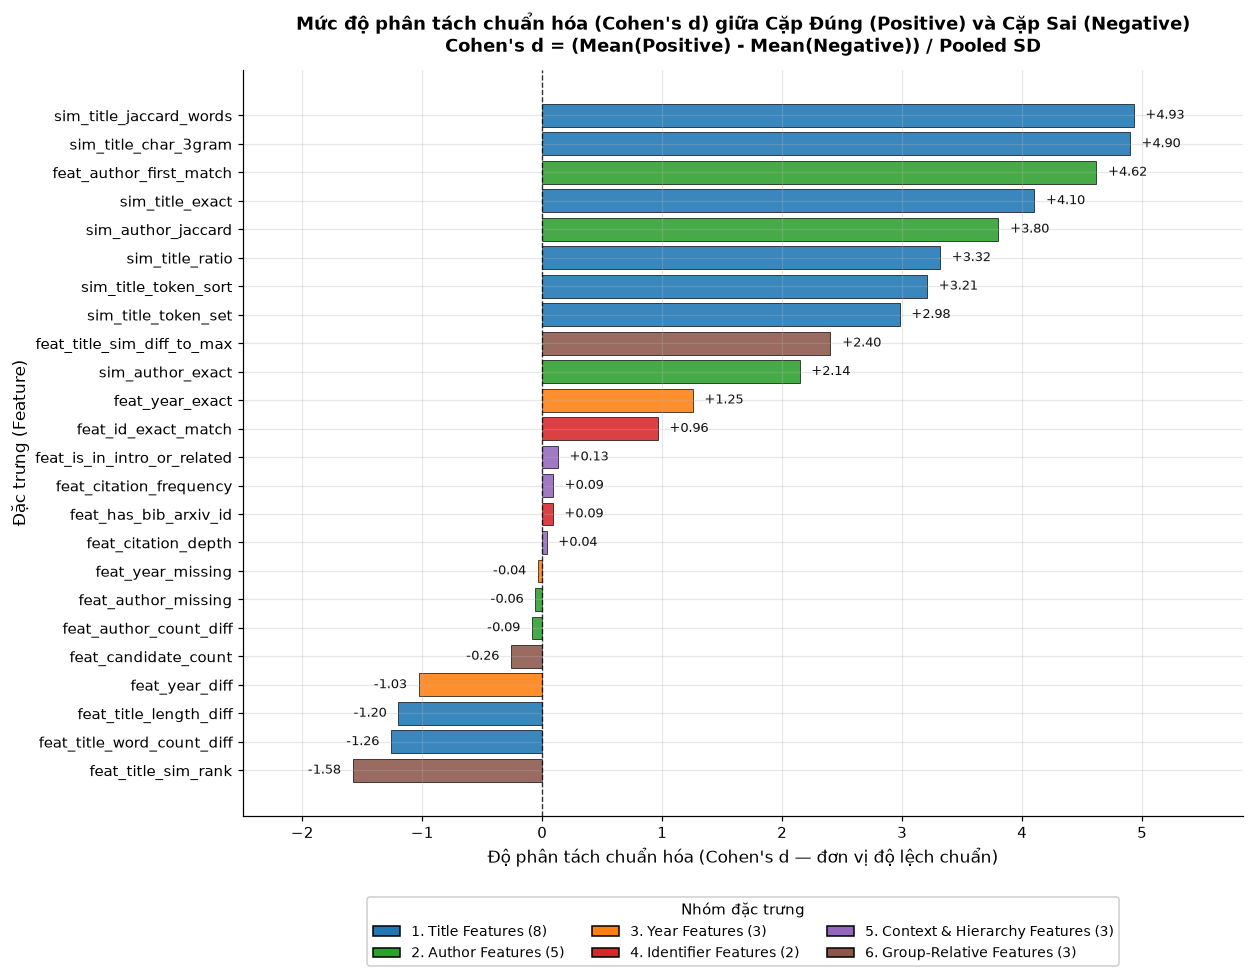

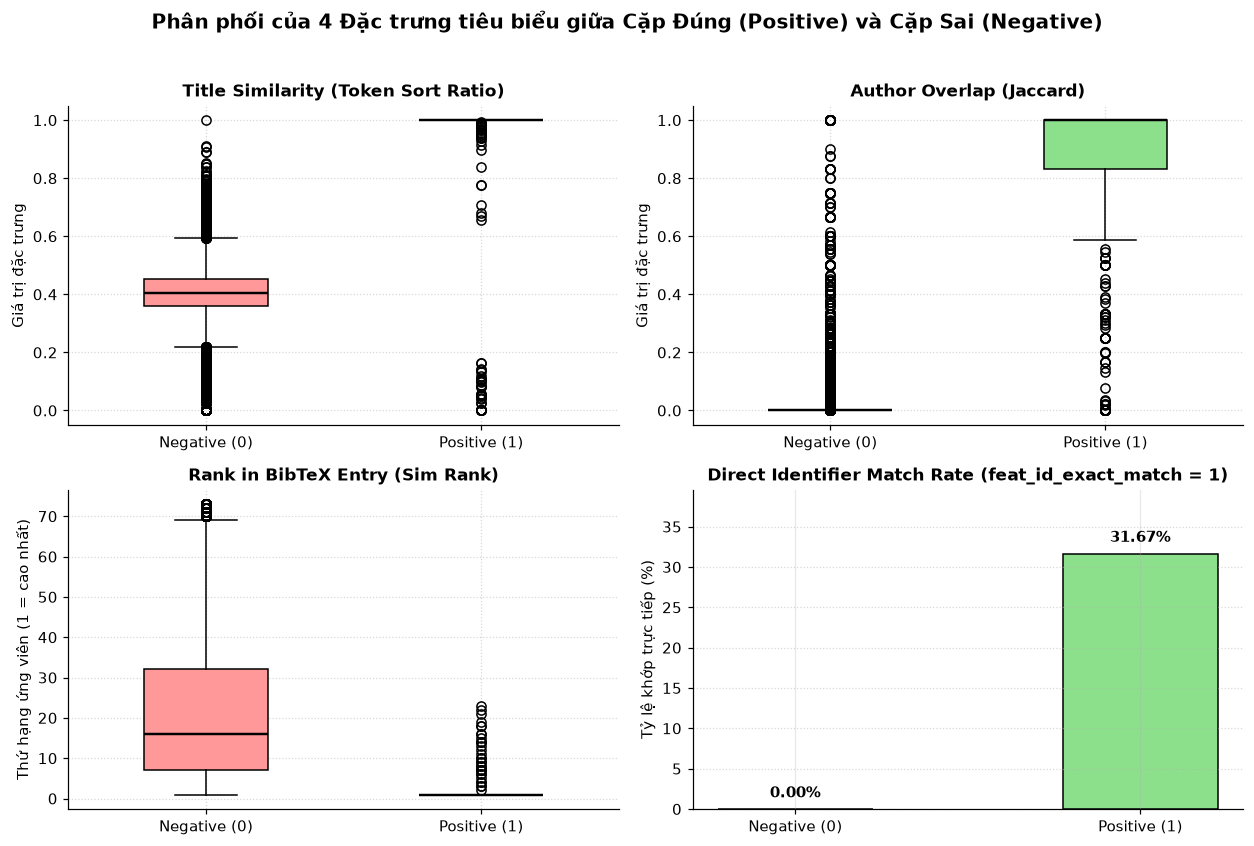

In [5]:
from matplotlib.patches import Patch

# 1. Biểu đồ thanh ngang (Horizontal Bar Chart) theo độ phân tách chuẩn hóa Cohen's d
fig, ax = plt.subplots(figsize=(11.5, 9.0), dpi=110)

group_palette = {
    "1. Title Features (8)": "#1f77b4",
    "2. Author Features (5)": "#2ca02c",
    "3. Year Features (3)": "#ff7f0e",
    "4. Identifier Features (2)": "#d62728",
    "5. Context & Hierarchy Features (3)": "#9467bd",
    "6. Group-Relative Features (3)": "#8c564b",
}

plot_data = separation_table.sort_values(by="Cohen's d", ascending=True)
colors = [group_palette.get(g, "#333333") for g in plot_data["Group"]]

bars = ax.barh(
    plot_data.index,
    plot_data["Cohen's d"],
    color=colors,
    alpha=0.88,
    edgecolor="black",
    linewidth=0.5,
)
ax.axvline(0, color="black", linestyle="--", linewidth=0.9, alpha=0.8)

min_val = float(plot_data["Cohen's d"].min())
max_val = float(plot_data["Cohen's d"].max())
span = max_val - min_val
ax.set_xlim(min_val - 0.14 * span, max_val + 0.14 * span)

ax.set_title(
    "Mức độ phân tách chuẩn hóa (Cohen's d) giữa Cặp Đúng (Positive) và Cặp Sai (Negative)\n"
    "Cohen's d = (Mean(Positive) - Mean(Negative)) / Pooled SD",
    fontsize=12,
    pad=12,
    fontweight="bold",
)
ax.set_xlabel("Độ phân tách chuẩn hóa (Cohen's d — đơn vị độ lệch chuẩn)", fontsize=11)
ax.set_ylabel("Đặc trưng (Feature)", fontsize=11)

# Ghi nhãn số rõ ràng bên ngoài đầu mỗi thanh (không đè thân cột)
pad = 0.015 * span
for bar in bars:
    val = bar.get_width()
    if val >= 0:
        ax.text(val + pad, bar.get_y() + bar.get_height() / 2, f"{val:+.2f}", va="center", ha="left", fontsize=8.5, color="#111111")
    else:
        ax.text(val - pad, bar.get_y() + bar.get_height() / 2, f"{val:+.2f}", va="center", ha="right", fontsize=8.5, color="#111111")

# Đặt chú thích bên dưới trục X để không bao giờ che khuất cột dữ liệu
legend_handles = [Patch(facecolor=color, edgecolor="black", label=group) for group, color in group_palette.items()]
ax.legend(
    handles=legend_handles,
    title="Nhóm đặc trưng",
    loc="upper center",
    bbox_to_anchor=(0.5, -0.10),
    ncol=3,
    framealpha=0.95,
    fontsize=9,
)

fig.tight_layout()
plt.show()

# 2. Biểu đồ phân phối cho 4 đặc trưng tiêu biểu (3 Boxplot + 1 Bar chart tỷ lệ khớp nhị phân)
fig, axes = plt.subplots(2, 2, figsize=(11.5, 7.8), dpi=110)

pos_data = matrix[matrix["label"] == 1.0]
neg_data = matrix[matrix["label"] == 0.0]

boxplot_specs = [
    ("sim_title_token_sort", "Title Similarity (Token Sort Ratio)", "Giá trị đặc trưng"),
    ("sim_author_jaccard", "Author Overlap (Jaccard)", "Giá trị đặc trưng"),
    ("feat_title_sim_rank", "Rank in BibTeX Entry (Sim Rank)", "Thứ hạng ứng viên (1 = cao nhất)"),
]

for idx, (feat, title, ylabel) in enumerate(boxplot_specs):
    ax = axes[idx // 2, idx % 2]
    bp = ax.boxplot(
        [neg_data[feat].dropna(), pos_data[feat].dropna()],
        tick_labels=["Negative (0)", "Positive (1)"],
        patch_artist=True,
        widths=0.45,
        medianprops=dict(color="black", linewidth=1.6),
    )
    bp["boxes"][0].set_facecolor("#ff9999")
    bp["boxes"][1].set_facecolor("#8ce08c")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.set_ylabel(ylabel, fontsize=10)
    ax.grid(True, linestyle=":", alpha=0.5)

# Ô thứ 4: Biểu đồ tỷ lệ khớp mã arXiv trực tiếp (biến nhị phân 0/1)
ax_id = axes[1, 1]
neg_id_rate = float(neg_data["feat_id_exact_match"].mean() * 100)
pos_id_rate = float(pos_data["feat_id_exact_match"].mean() * 100)
id_bars = ax_id.bar(
    ["Negative (0)", "Positive (1)"],
    [neg_id_rate, pos_id_rate],
    color=["#ff9999", "#8ce08c"],
    edgecolor="black",
    width=0.45,
)
ax_id.set_ylim(0, max(pos_id_rate * 1.25, 10.0))
ax_id.set_title("Direct Identifier Match Rate (feat_id_exact_match = 1)", fontsize=11, fontweight="bold")
ax_id.set_ylabel("Tỷ lệ khớp trực tiếp (%)", fontsize=10)
ax_id.grid(True, axis="y", linestyle=":", alpha=0.5)
for bar, rate in zip(id_bars, [neg_id_rate, pos_id_rate]):
    ax_id.text(bar.get_x() + bar.get_width() / 2, rate + 1.0, f"{rate:.2f}%", ha="center", va="bottom", fontsize=10, fontweight="bold")

fig.suptitle("Phân phối của 4 Đặc trưng tiêu biểu giữa Cặp Đúng (Positive) và Cặp Sai (Negative)", fontsize=13, fontweight="bold")
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()


## 6. Kết luận & Đóng góp vào Báo cáo Chung

1. **Về Auto-Labeling Pipeline:**
   - Đạt độ chính xác **Precision = 99.77%** và độ bao phủ **Recall = 94.26%** trên 20 bài manual pool (881 mục trích dẫn). Kết quả này khẳng định bộ 4 quy tắc Heuristic trong `AutoReferenceMatcher` có độ tin cậy rất cao, hạn chế tối đa rủi ro gán nhãn sai (label noise) khi tạo dữ liệu huấn luyện tự động.
   - Kết quả kiểm định chi tiết đã được đồng bộ lưu trữ tại `data/matching/auto_label_validation.json`.

2. **Về Feature Engineering:**
   - Xây dựng thành công **6 nhóm với 24 đặc trưng** đa chiều, phản ánh đầy đủ thông tin từ cú pháp tiêu đề, tác giả, năm xuất bản, định danh arXiv đến ngữ cảnh vị trí trích dẫn trong cây phân cấp Milestone 2 (`feat_citation_depth`, `feat_citation_frequency`, `feat_is_in_intro_or_related`).
   - Phân tích phân tách chuẩn hóa (Cohen's $d$) cho thấy nhóm **Title Features** (`sim_title_exact`, `sim_title_jaccard_words`, `sim_title_char_3gram`, `sim_title_token_sort`), **Author Features** (`feat_author_first_match`, `sim_author_jaccard`) và **Group-Relative Features** (`feat_title_sim_diff_to_max`, `feat_title_sim_rank`) tách biệt cực mạnh giữa cặp đúng và cặp nhiễu.
   - Nhóm **Identifier Features** (`feat_id_exact_match`) có tỷ lệ dương tính giả gần như bằng `0%` (`0.00%` trên Negative so với `31.67%` trên Positive), đóng vai trò tín hiệu xác thực cứng cực kỳ tin cậy.
   - **Lưu ý về nhóm Context & Hierarchy (M2):** Dù trên toàn bộ ma trận ứng viên có độ lệch trung bình nhẹ (do các mục có match thường được trích dẫn nhiều hơn đôi chút), trong **nội bộ từng mục BibTeX**, 3 đặc trưng ngữ cảnh này nhận cùng một giá trị cho mọi ứng viên $j$. Do đó, chúng không tự làm đổi thứ tự xếp hạng trong các mô hình tuyến tính pointwise (nhất quán với kết quả Ablation $\Delta = 0.0000$ ở báo cáo Modeling) mà chủ yếu hữu ích khi kết hợp với mô hình phi tuyến hoặc tương tác đặc trưng.

3. **Bàn giao cho Modeling & Poster:**
   - Toàn bộ ma trận ứng viên `candidate_matrix.parquet` (34.377 cặp) đã được bàn giao sẵn sàng cho giai đoạn huấn luyện và đánh giá các mô hình xếp hạng tiếp theo của nhóm (Logistic Regression, Gradient Boosting, Random Forest).
   - Các bảng chỉ số và biểu đồ phân tách chuẩn hóa đã sẵn sàng để trình bày trên Poster A2 của nhóm.
